In [1]:
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import os

In [2]:
DATAPATH = '../../data/output'
RESULTS = 'search_q_net_layer_experiments_20211104-004343.csv'

# Configuration
EPISODES = 5000
EPS_DECAY = 0.99
EPS_MIN = 0.05
BUFFERSIZE = 500
MIN_EXP = 100
BATCH_SIZE = 50
UPDATE_THRESHOLD = 1000

In [3]:
results = pd.read_csv(os.path.join(DATAPATH, RESULTS))

# %%
# results = results[results['penalty'] == 15]
results['return_MA'] = results['return'].rolling(20).mean()
results['service_level_MA'] = results['service_level'].rolling(20).mean()

FileNotFoundError: [Errno 2] No such file or directory: '../../data/output\\search_q_net_layer_experiments_20211104-004343.csv'

NameError: name 'results' is not defined

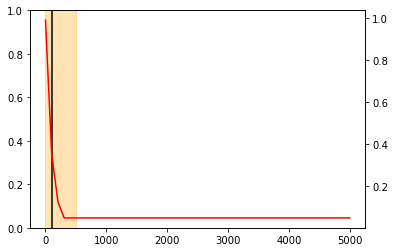

In [5]:
fig, ax = plt.subplots()
# annotations
plt.axvspan(0, BUFFERSIZE, color='orange', alpha=.3, label='buffersize')
plt.axvline(MIN_EXP, color='black', label='training start')
x_ = np.linspace(1,EPISODES)
ax_ = plt.twinx(ax)
ax2 = ax.twinx()
sns.lineplot(x=x_, y=np.maximum(EPS_DECAY**x_, EPS_MIN), color='red', ax=ax2, label=f'epsilon (1->{EPS_MIN})', legend=False)
ax_.set_axis_off() # hide this axis

sns.lineplot(data=results, x='episode', y='return', alpha=.2, color='blue', label='return', ax=ax, legend=False)
sns.lineplot(data=results, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax, legend=False)
sns.lineplot(data=results, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
sns.lineplot(data=results, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)

plt.title('Experiment with Penalty = 15, soft update with tau=0.001 at every step')
fig.patch.set_facecolor('white')
ax2.set_ylabel('service level / eps')
fig.legend(bbox_to_anchor=(1.04,0.5), loc="center left")
fig.show()

In [6]:
BENCHMARK = '100_episodes_benchmark_20211108-152540.csv'
ROLLING = 10

In [7]:
benchmark_results = pd.read_csv(os.path.join(DATAPATH, BENCHMARK))
# noinspection JupyterPackage
benchmark_results.loc[benchmark_results['type']=='DQN', 'service_level_MA'] = benchmark_results.loc[benchmark_results['type']=='DQN', 'service_level'].rolling(ROLLING).mean()
benchmark_results.loc[benchmark_results['type']=='benchmark (planned)', 'service_level_MA'] = benchmark_results.loc[benchmark_results['type']=='benchmark (planned)', 'service_level'].rolling(ROLLING).mean()

sns.lineplot(data=benchmark_results, x='episode', y='service_level_MA', hue='type')

FileNotFoundError: [Errno 2] No such file or directory: '../../data/output\\100_episodes_benchmark_20211108-152540.csv'

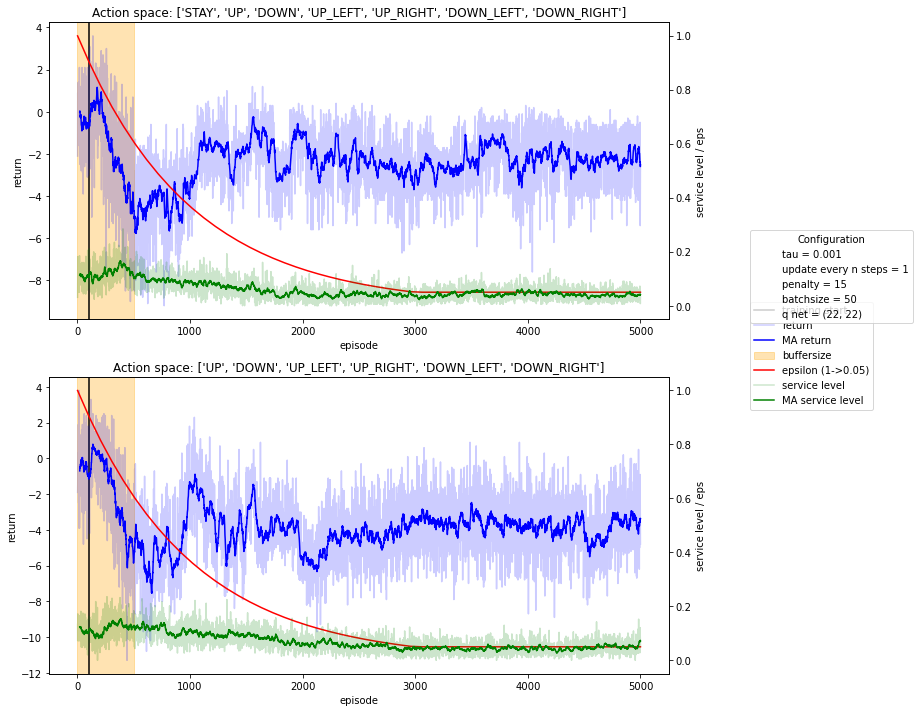

In [4]:
import matplotlib.patches as mpatches
EPS_DECAY = 0.999

config = {
    'tau': 0.001,
    'update every n steps': 1,
    'penalty': 15,
    'batchsize': 50,
    'q net': (22,22)
}

RESULTS = 'search_action_space_experiments_averaged_10_20211121-103542.csv'
results = pd.read_csv(os.path.join(DATAPATH, RESULTS))

if 'buffersize' in list(results):
    fig, ax = plt.subplots(results['buffersize'].nunique(), figsize=(10,15))
    for i, (name, group) in enumerate(results.groupby('buffersize')):
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        ax[i].axvspan(0, name, color='orange', alpha=.3, label='buffersize')
        ax[i].axvline(MIN_EXP, color='black', label='training start')

        x_ = np.linspace(1,EPISODES)
        ax_ = ax[i].twinx()
        ax2 = ax[i].twinx()
        sns.lineplot(x=x_, y=np.maximum(EPS_DECAY**x_, EPS_MIN), color='red', ax=ax2, label=f'epsilon (1->{EPS_MIN})', legend=False)
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', alpha=.2, color='blue', label='return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
        sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[i].set_title(f'Buffersize: {name}')

if 'action_space' in list(results):
    experiments = results['action_space'].nunique()
    fig, ax = plt.subplots(experiments, figsize=(10,5*experiments))
    for i, (name, group) in enumerate(results.groupby('action_space')):
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        ax[i].axvspan(0, BUFFERSIZE, color='orange', alpha=.3, label='buffersize')
        ax[i].axvline(MIN_EXP, color='black', label='training start')

        x_ = np.linspace(1,EPISODES)
        ax_ = ax[i].twinx()
        ax2 = ax[i].twinx()
        sns.lineplot(x=x_, y=np.maximum(EPS_DECAY**x_, EPS_MIN), color='red', ax=ax2, label=f'epsilon (1->{EPS_MIN})', legend=False)
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', alpha=.2, color='blue', label='return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
        sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[i].set_title(f'Action space: {name}')

handles, labels = [(a + b) for a, b in zip(ax[i].get_legend_handles_labels(), ax2.get_legend_handles_labels())]
fig.patch.set_facecolor('white')
fig.tight_layout()
# fig.suptitle('Experiment with Penalty = 15, soft update with tau=0.001 at every step', fontsize=15)
# fig.subplots_adjust(top=0.95)
lgd = fig.legend(handles, labels, bbox_to_anchor=(1.04,0.5), loc="center left")
config_handles = []
for k,v in config.items():
    config_handles.append(mpatches.Patch(color='none', label=f'{k} = {v}'))
lgd2 = fig.legend(handles=config_handles, bbox_to_anchor=(1.04,0.61), loc="center left", title="Configuration")

plt.savefig(os.path.join(DATAPATH, RESULTS.replace('.csv', '.png')), bbox_extra_artists=(lgd,lgd2), bbox_inches='tight')
plt.show()

In [91]:
results.groupby(['buffersize', 'episode']).mean().reset_index()[list(results)] == results

,episode,return,service_level,buffersize
0,True,True,True,True
1,True,True,True,True
2,True,True,True,True
3,True,True,True,True
4,True,True,True,True
...,...,...,...,...
14995,True,True,True,True
14996,True,True,True,True
14997,True,True,True,True
14998,True,True,True,True
